# Self-learning 1 — Advanced Hyperparameter Optimization with Optuna

**Optional extension · Data Analytics bootcamp**

In **7.4 — Hyperparameter Tuning**, we used `GridSearchCV` and `RandomizedSearchCV` to tune complete pipelines. This notebook revisits the same ideas with **Optuna**, then introduces an adaptive search strategy called **TPE**.

**Learning goals**
- Understand Optuna's *study*, *trial*, *objective function* and *sampler*.
- Run **grid**, **random** and **TPE** searches on the **same regression pipeline**.
- Inspect optimization history, parameter relationships and hyperparameter importance.
- Explain conceptually how Optuna's TPE differs from the Bayesian optimization commonly used by `BayesSearchCV`.
- Preserve an untouched test set and distinguish CV selection scores from final evaluation.

**Prerequisites:** `Pipeline`, cross-validation, MAE, and hyperparameter tuning from **7.4 — Hyperparameter Tuning**.

**Scope:** statistical confidence intervals, nested CV and repeated nested CV belong to **Self-learning 2**.

## 1. From search methods to a search framework

`GridSearchCV` and `RandomizedSearchCV` combine search, cross-validation and refitting in a single scikit-learn estimator. Optuna separates these responsibilities:

- An **objective function** evaluates one candidate configuration and returns a numerical score.
- A **trial** represents one evaluated configuration.
- A **sampler** chooses which configuration to try next.
- A **study** manages trials and tracks the best result.

The *sampler* is what changes between grid, random and TPE search. We keep the **dataset, pipeline, scoring metric and CV folds** the same. Grid Search uses a small finite grid; Random Search and TPE explore a broader common search space.

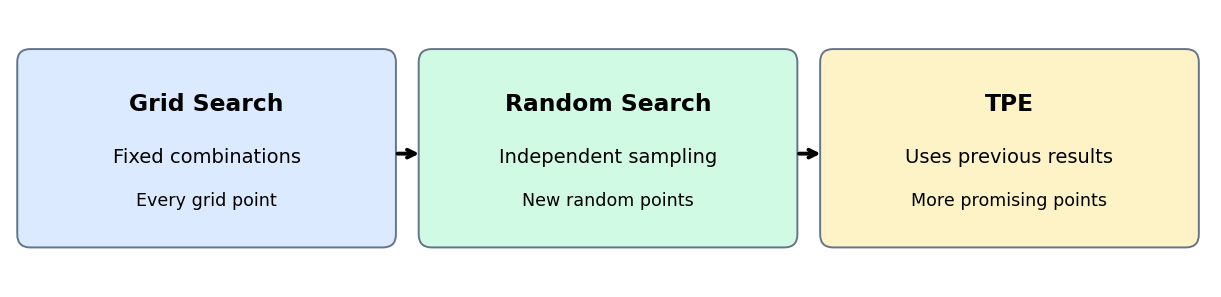

## 2. Setup and reproducible data

We use scikit-learn's built-in **Diabetes regression** dataset. It is small and requires no dataset download. We keep a separate **test set** untouched until the final section.

Install the required packages in your Conda environment before running this notebook. Plotly powers the interactive charts in Section 6. **`optuna-dashboard` is optional:** it provides a separate dashboard interface and is not required for `optuna.visualization` plots.

In [ ]:
# Run these commands in a terminal, with your Conda environment activated:
# conda install -c conda-forge optuna plotly ipywidgets
#
# Optional standalone study dashboard (not required by this notebook):
# conda install -c conda-forge optuna-dashboard
#
# Restart the Python kernel after installing packages if necessary.

In [ ]:
import numpy as np
import pandas as pd
import optuna
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

RANDOM_STATE = 42
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
cv = KFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
print(f"Training: {X_train.shape}; Test: {X_test.shape}")

### A shared pipeline and search spaces

We tune a `RandomForestRegressor`. Tree models do not require scaling, so the pipeline contains only the estimator. We use `model__...` to configure parameters of the estimator inside the pipeline, as in **7.4 — Hyperparameter Tuning**.

**Optuna trial suggestions**

```python
trial.suggest_int(hyperparameter_name, minimum_value, maximum_value, step=1)
trial.suggest_categorical(hyperparameter_name, choices)
```

- `suggest_int("max_depth", 2, 10, step=2)` chooses among **2, 4, 6, 8, 10**. The endpoints are inclusive when reached by the step.
- `suggest_categorical("criterion", ["squared_error", "absolute_error"])` chooses from explicitly listed options. It also accepts numeric or Boolean choices, not only strings.

We will use **two values per hyperparameter** for Grid Search, and wider integer ranges for Random Search and TPE. These ranges are teaching choices, not universally optimal settings.


In [ ]:
def make_pipeline():
    """Return a fresh, unfitted regression pipeline."""
    return Pipeline([
        ("model", RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1,
        ))
    ])


def evaluate_configuration(params):
    """Return positive mean MAE across the four validation folds."""
    pipeline = make_pipeline()
    pipeline.set_params(**{
        f"model__{key}": value for key, value in params.items()
    })
    # scikit-learn scorers follow "higher is better": MAE is negated.
    negative_mae_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
    )
    mae_scores = -negative_mae_scores
    mean_mae = float(mae_scores.mean())
    return mean_mae  # Positive MAE: lower is better.


# Small, exhaustively searchable grid: 2 x 2 x 2 = 8 trials.
GRID_SPACE = {
    "n_estimators": [30, 60],
    "max_depth": [3, 7],
    "min_samples_leaf": [2, 6],
}

# Larger domain: 8 x 9 x 8 = 576 possible configurations.
# Random Search and TPE will use these same ranges.
WIDE_SPACE = {
    "n_estimators": (30, 100, 10),
    "max_depth": (2, 10, 1),
    "min_samples_leaf": (1, 8, 1),
}

print("Grid combinations:", np.prod([len(v) for v in GRID_SPACE.values()]))
print("Wide-space combinations:", 8 * 9 * 8)


## 3. Grid search with Optuna

`GridSampler` visits **every combination** in the finite grid, analogous to `GridSearchCV`. The objective uses `suggest_int()` with steps matching the grid's candidate values.

**Check for understanding:** With two values for each of three hyperparameters, how many trials are needed? With four-fold CV, how many model fits are performed?

<details>
<summary>Answer</summary>

There are **2 × 2 × 2 = 8 trials**. Each trial fits four models, so **8 × 4 = 32 fits**. A subsequent final refit would add one more fit.

</details>


In [ ]:
def grid_objective(trial):
    """Evaluate one candidate from the small finite grid."""
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 30, 60, step=30),
        "max_depth": trial.suggest_int("max_depth", 3, 7, step=4),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 6, step=4),
    }
    return evaluate_configuration(params)


grid_sampler = optuna.samplers.GridSampler(GRID_SPACE)
grid_study = optuna.create_study(direction="minimize", sampler=grid_sampler)
grid_study.optimize(grid_objective, n_trials=8, show_progress_bar=True)

print("Grid best CV MAE:", round(grid_study.best_value, 2))
print("Grid best parameters:", grid_study.best_params)


### Why is the score negated and then minimized?

`cross_val_score(scoring="neg_mean_absolute_error")` returns **negative MAE** because scikit-learn's scoring convention is *higher is better*. Our `evaluate_configuration()` function explicitly changes its sign and returns **positive mean MAE**. Therefore, `optuna.create_study(direction="minimize")` consistently seeks the **lowest MAE**.


## 4. Random search with Optuna

`RandomSampler` chooses configurations **without using previous trial scores**. Unlike Grid Search, we now explore a much larger domain: **576 possible combinations**, but evaluate only **8 trials**. Random sampling may revisit the same configuration; it does not guarantee unique trials.

We reuse the same evaluation function, but define a new objective with broader integer ranges. This makes the distinction between *exhaustively searching a small grid* and *sampling a large space* clear.


In [ ]:
def wide_objective(trial):
    """Evaluate one configuration from the larger shared search space."""
    params = {
        name: trial.suggest_int(name, low, high, step=step)
        for name, (low, high, step) in WIDE_SPACE.items()
    }
    return evaluate_configuration(params)


random_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.RandomSampler(seed=RANDOM_STATE),
)
random_study.optimize(wide_objective, n_trials=8, show_progress_bar=True)

print("Random best CV MAE:", round(random_study.best_value, 2))
print("Random best parameters:", random_study.best_params)


## 5. TPE — learning where to search

**Tree-structured Parzen Estimator (TPE)** is an adaptive probabilistic search strategy. Unlike Random Search, its later suggestions depend on earlier trials.

1. Run a few exploratory trials.
2. Sort completed trials by objective value (here, **lower MAE is better**).
3. Divide trials into a relatively small **good** group and the **remaining** group.
4. Estimate two probability density models of the hyperparameters:

   - **l(x) = P(x | good)** — configurations observed among the good trials.
   - **g(x) = P(x | bad)** — configurations observed among the remaining trials.

5. Favor candidates with a large **l(x) / g(x)** ratio: configurations that are more characteristic of good results than of the remaining results.

### How is the split chosen?

Optuna's default `TPESampler` uses a function called `gamma` to determine the number of good trials. For a **single-objective** study, the default is approximately the best 10%, capped at 25 completed trials:

\[
n_{\mathrm{good}} = \min(\lceil 0.1n\rceil,\,25)
\]

For example, after 20 completed trials, the **2 lowest-MAE trials** belong to the good group; the other 18 belong to the remaining group. This is the **10th percentile of MAE**, not the 90th, because we are minimizing.

### Why the ratio, rather than just l(x)?

A configuration may be common among good trials **and** among bad trials. The ratio rewards values that distinguish the good group from the rest. By Bayes' theorem:

\[
\frac{P(\mathrm{good}\mid x)}{P(\mathrm{bad}\mid x)}
=
\frac{l(x)}{g(x)}
\cdot
\frac{P(\mathrm{good})}{P(\mathrm{bad})}
\]

The prior-odds factor is fixed for a given split, so maximizing the density ratio also maximizes these posterior odds **within the estimated probabilistic model**.

| `max_depth` | l(x) | g(x) | l(x) / g(x) |
|---|---:|---:|---:|
| 3 | 0.40 | 0.50 | 0.80 |
| 6 | 0.35 | 0.10 | **3.50** |
| 9 | 0.25 | 0.40 | 0.625 |

*Illustrative discrete probabilities, not actual results from the study.* Maximizing l(x) alone would choose depth 3; the ratio prefers depth 6.

**Statistical caution:** the good group contains fewer observations, so l(x) may be less precisely estimated. Very small estimates of g(x) can also make the ratio unstable. TPE uses smoothing and prior information to help, but its suggestions are not guarantees.

**Check for understanding:** What happens to the reliability and selectivity of l(x) if we include a larger fraction of trials in the good group?

We use four random startup trials, followed by adaptive sampling. We explore the **same wide search space** as Random Search, with a larger trial budget to illustrate how the method learns.


In [ ]:
tpe_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE,
        n_startup_trials=4,
    ),
)
tpe_study.optimize(wide_objective, n_trials=20, show_progress_bar=True)

print("TPE best CV MAE:", round(tpe_study.best_value, 2))
print("TPE best parameters:", tpe_study.best_params)


### Compare the searches

All three methods use the **same dataset, pipeline, scoring and four CV folds**, but they differ in search space and/or trial budget:

- **Grid:** 8 trials, exhaustive search of 8 configurations.
- **Random:** 8 trials sampled from 576 possible configurations.
- **TPE:** 20 trials from the same 576-configuration domain, with adaptive sampling after 4 startup trials.

Therefore, this table **does not provide a controlled ranking of search algorithms**. It illustrates how the strategies behave. A lower CV MAE is better; do not use the test set to choose which strategy to run next.


In [ ]:
studies = {"Grid": grid_study, "Random": random_study, "TPE": tpe_study}
comparison = pd.DataFrame([
    {
        "Search": name,
        "Trials": len(study.trials),
        "Best CV MAE": round(study.best_value, 2),
        "Best parameters": study.best_params,
    }
    for name, study in studies.items()
]).sort_values("Best CV MAE")
display(comparison)

## 6. Visualizing the optimization

Optuna integrates with Plotly for interactive figures. The visualizations below are **generated by code**, not linked to external images. They require Plotly and a frontend capable of displaying interactive figures. `optuna-dashboard` is a separate, optional interface.

- **Optimization history:** which trials improved the best observed score?
- **Slice plot:** how does the observed score vary with each hyperparameter?
- **Hyperparameter importance:** which search dimensions appear most influential **within this study**?

**Caution:** hyperparameter importance is not feature importance, and these plots show associations within the explored search space, not causal effects.

In [ ]:
import optuna.visualization as vis

vis.plot_optimization_history(tpe_study).show()

In [ ]:
vis.plot_slice(tpe_study).show()

In [ ]:
# This analysis is more informative with more trials and a larger search space.
vis.plot_param_importances(tpe_study).show()

### Interpreting the plots

A good configuration may arise from **interactions** between hyperparameters. A slice plot collapses over the other settings; a high importance value does not mean a parameter always matters most for every dataset.

**Check for understanding:** Does `n_estimators` influence the number of trees or the values of their learned split thresholds? Which are hyperparameters and which are learned parameters?

## 7. TPE vs. `BayesSearchCV`: what is the conceptual difference?

Both approaches are **sequential model-based optimization**: they use results of previous evaluations to guide later choices. However, their default probabilistic models differ.

| | `BayesSearchCV` (typical/default setup) | Optuna `TPESampler` |
|---|---|---|
| Package | `scikit-optimize` | `optuna` |
| Main idea | Build a surrogate model of **score as a function of hyperparameters** | Build density models of **hyperparameters conditional on good/bad scores** |
| Default probabilistic approach | Gaussian-process surrogate (alternatives exist) | Tree-structured Parzen estimator |
| Next candidate | Optimize an acquisition function using the surrogate | Favor candidates with a high estimated l(x) / g(x) density ratio |
| API | scikit-learn search-estimator interface | `Study` + `Trial` + `Sampler` |

**Intuition:** a Gaussian-process approach asks *“what score might I obtain at this point, and how uncertain am I?”*; TPE asks *“which values look characteristic of successful trials rather than unsuccessful ones?”*

The term *Bayesian optimization* describes a broad family of approaches; TPE is commonly included in that family. Neither method is guaranteed to outperform grid or random search on every problem.

**Optional reading:** [scikit-optimize BayesSearchCV](https://scikit-optimize.github.io/stable/modules/generated/skopt.BayesSearchCV.html) · [Optuna TPESampler](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)

## 8. Final refit and independent test evaluation

Optuna does **not** automatically refit a scikit-learn pipeline. In contrast, `GridSearchCV(refit=True)` does.

After choosing a configuration based on training-set CV results, we must create a **fresh pipeline**, set its hyperparameters and fit it on **all training observations**. Only then do we evaluate once on the untouched test set.

Below we use the configuration with the lowest observed CV MAE across our demonstration studies. This is a pedagogical illustration: comparing multiple search studies and choosing the best observed CV score can itself introduce selection optimism. The independent test set remains necessary.

In [ ]:
selected_name = comparison.iloc[0]["Search"]
selected_study = studies[selected_name]

best_pipeline = make_pipeline()
best_pipeline.set_params(**{
    f"model__{name}": value
    for name, value in selected_study.best_params.items()
})
best_pipeline.fit(X_train, y_train)

y_pred_test = best_pipeline.predict(X_test)
test_mae = mean_absolute_error(y_test, y_pred_test)

print("Selected search:", selected_name)
print("Selected CV MAE:", round(selected_study.best_value, 2))
print("Independent test MAE:", round(test_mae, 2))

## 9. Optional practice

1. Change the candidate values for `max_depth` in **both `GRID_SPACE` and `grid_objective`**, keeping two values. Rerun the grid study. What changed?
2. Increase the TPE trial budget. Does its best observed score improve? Why can it never get worse as the trial count increases, even though the next individual trial can be worse?
3. Change the random seed used by `RandomSampler`. Do you obtain the same best configuration?
4. **Stretch:** adapt `make_pipeline()` and the objective to tune a `GradientBoostingRegressor` instead. Which hyperparameters would you choose?

Keep `X_test` untouched while experimenting. Repeatedly checking test performance to decide what to try next turns the test set into another validation set.

## Recap

- Optuna's **sampler** determines the search strategy; the **objective** determines how configurations are evaluated.
- Grid Search exhaustively explores a small grid; Random Search samples a larger space; TPE uses previous trials and estimated good/bad density ratios to guide sampling.
- TPE and the Gaussian-process approach commonly used by `BayesSearchCV` are conceptually different forms of sequential probabilistic optimization.
- Optuna visualizations reveal patterns in the **search**, not definitive feature importance or causal relationships.
- **CV scores are estimates**, and the best observed CV score may be optimistic after extensive searching.
- Optuna requires a **manual refit** of the chosen pipeline; `GridSearchCV(refit=True)` performs this step automatically.

**Next self-learning notebook:** progressively estimating model performance with hold-out, K-fold CV, nested CV and repeated nested CV, including the limitations of naive confidence intervals.